In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
#build vocabulary of characters and mappings to/from int
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:

#set a blocksize i.e. how many characters will be considered at a time
blocksize = 3


######build the dataset WITH SPLITS
def build_dataset(words):

    #create an X and Y mapping arrays
    X, Y = [],[]
    
    #for every word
    
    for w in words:
        #create a context list of length blocksize
        context = [0]*blocksize
    
        for ch in w + '.':
            #get the index of the char
            ix = stoi[ch]
            #add the context that produced this char to X list
            X.append(context)
            
            #add the output (ix) to the Y list
            Y.append(ix)
            
            #crop and append the context
            context = context[1:]+[ix]
        #set X and Y to torch tensors
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

#split the dataset
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])



In [8]:

n_embed = 10
n_hidden = 200


g = torch.Generator().manual_seed(2147483647)

C = torch.randn(27, n_embed,                     generator=g)
W1 = torch.randn((n_embed*blocksize, n_hidden),  generator=g) * (5/3) / ((n_embed*blocksize)**0.5) #* 0.15
#b1 = torch.randn(n_hidden,                       generator=g) * 0.001
W2 = torch.randn((n_hidden, 27),                 generator=g) * 0.01
b2 = torch.randn(27,                             generator=g) * 0.0 #could be torch.zeros?
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

params = [C, W1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in params))
for p in params:
    p.requires_grad = True

12097


In [9]:
stepi = []
lri = []
lossi = []
steps = 200000
batch_size = 32

for i in range(steps): 
    #minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix]
    
    
    #forward pass
    emb = C[Xb] #embed inputs in feature vectors 
    embcat = emb.view(emb.shape[0], -1) 
    hpreact = embcat @ W1 # hidden layer preactivation
    #batch normalization ~ subtract mean, divide by standard deviation
    #only want to do this at initialization though...so we also train a gain and bias for batchnorm
    #hidden cost for this is coupling the inputs from each batch, which will change the 
    #activations for any example based on what else is in the batch
    #however, this 'jitter' added via batchnorm helps prevent overfitting by adding noise
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi =  hpreact.std(0, keepdim=True)
    hpreact = hpreact - bngain * bnmeani / bnstdi + bnbias

    #keep track of typical mean and std 
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001*bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001*bnstdi
    
    h = torch.tanh(hpreact) # hidden layer activation
    logits = h @ W2 + b2 # raw NN outputs ranging +- around 0
    loss = F.cross_entropy(logits, Yb) #softmax classification of logits, forward and backward much more efficient, fewer bugs

    
    #backward pass
    for p in params:
        p.grad = None
    
    loss.backward()

    lr = 0.1
    if i > steps*0.75:
        lr = 0.01
        
    for p in params:
        p.data += -lr*p.grad

    if i% 10000 == 0:
        print(f'{i:7d}/{steps:7d}: {loss.item():.4f}')
    # #track stats
    # lri.append(lre[i])
    lossi.append(loss.log10().item())


print(loss.item())

      0/ 200000: 3.3378
  10000/ 200000: 1.8862
  20000/ 200000: 1.9231
  30000/ 200000: 2.5287
  40000/ 200000: 2.5920
  50000/ 200000: 2.0520
  60000/ 200000: 2.1081
  70000/ 200000: 2.1377
  80000/ 200000: 2.3662
  90000/ 200000: 2.1495
 100000/ 200000: 2.3904
 110000/ 200000: 2.0177
 120000/ 200000: 2.0712
 130000/ 200000: 2.6385
 140000/ 200000: 2.3036
 150000/ 200000: 2.0594
 160000/ 200000: 2.1560
 170000/ 200000: 1.6549
 180000/ 200000: 2.4969
 190000/ 200000: 1.7562
2.0877315998077393


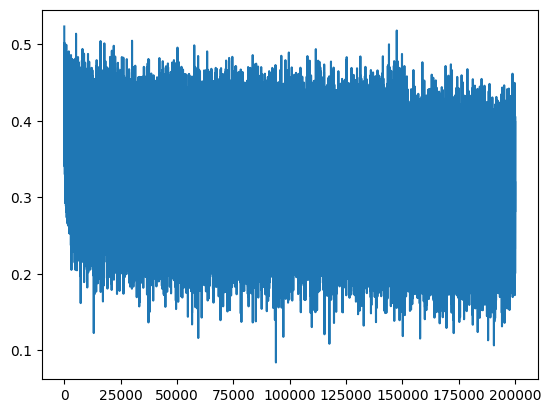

In [10]:
plt.plot(lossi)

In [11]:
@torch.no_grad() # decorator disables gradient tracking
def split_loss(split):
    x,y = {
        'train':(Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]
    
    emb = C[x] #embed inputs in feature vectors 
    embcat = emb.view(emb.shape[0], -1) # concat into (features, examples)
    hpreact = torch.tanh(embcat @ W1)
    hpreact = hpreact - bngain * bnmean_running / bnstd_running + bnbias #use _running mean and std for inference instead of calculating onthe fly

    logits = hpreact @ W2 + b2 # raw NN outputs ranging +- around 0
    loss = F.cross_entropy(logits, y) #softmax classification of logits, forward and backward much more efficient, fewer bugs
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.1709396839141846
val 2.2575743198394775


In [36]:
#sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

# for some number of words
for _ in range(20):
    #initialize outputs and context
    out = []
    context = [0]*blocksize
    while True:
        #forward pass neural net
        emb = C[torch.tensor([context])]
        embcat = emb.view(emb.shape[0], -1) # concat into (N, blocksize * n_embd
        hpreact = torch.tanh(embcat @ W1)# + b1) #use view to reshape [32, 3, 2] ----> [32, 6] for matmul
        hpreact = hpreact - bngain * bnmean_running / bnstd_running + bnbias #use _running mean and std for inference instead of calculating onthe fly
    
        logits = hpreact @ W2 + b2 # raw NN outputs ranging +- around 0
        probs = F.softmax(logits, dim = 1)
        #sample from the distribution
        ix = torch.multinomial(probs, num_samples = 1, generator=g).item()
        #shift context window and track samples
        context = context[1:] + [ix]
        out.append(ix)
        #if we sample the special '.' token, break
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

carmaira.
elie.
khi.
mili.
emilah.
cassie.
rahien.
emery.
calaeli.
arlenia.
chaiha.
emie.
eve.
amoni.
edeniyah.
roie.
alia.
biara.
elo.
ierrini.
